In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def ecual(img):
    resimg = img.copy()
    hist = cv2.calcHist([img], [0], None, [256], [0,256]).ravel().astype(int)
    freq_acum = np.cumsum(hist)
    N_pixeles = img.size
    FE = 255 / N_pixeles
    LUT = np.rint(FE * freq_acum).astype(np.uint8)
    filas, cols = img.shape
    for i in range(filas):
        for j in range(cols):
            resimg[i, j] = LUT[img[i, j]]

    return resimg

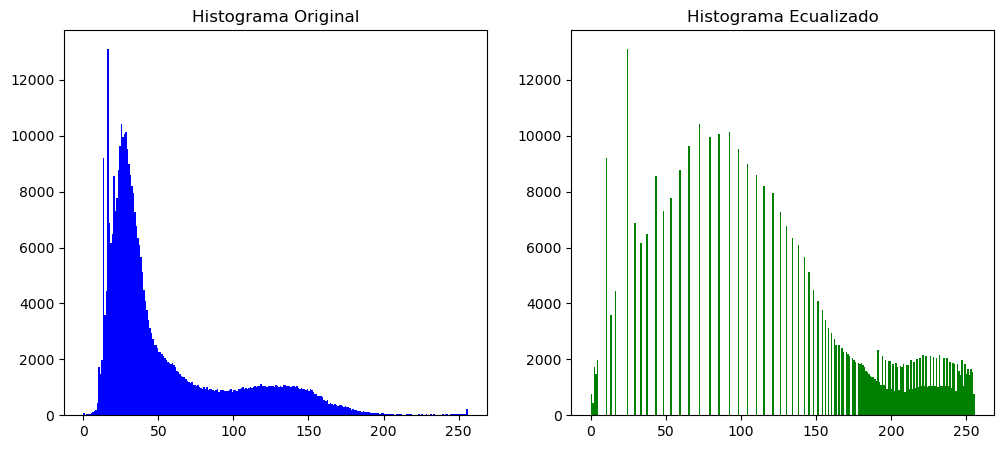

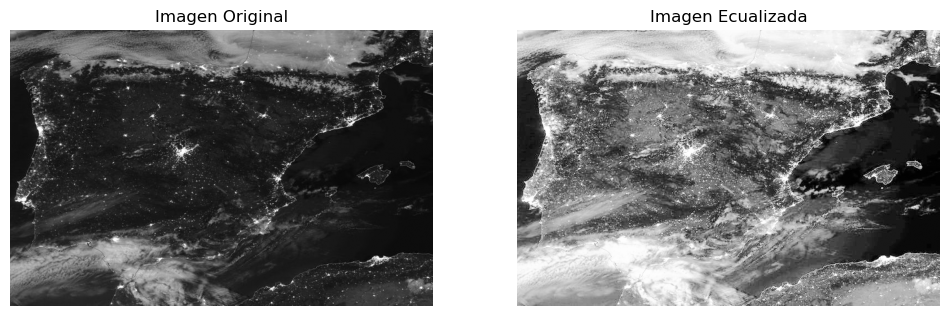

In [2]:
img = cv2.imread("satelite.jpg", cv2.IMREAD_GRAYSCALE)

img_ecual = ecual(img)

#Histogramas
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.hist(img.ravel(), bins=256, range=(0,256), color="blue")
plt.title("Histograma Original")

plt.subplot(1,2,2)
plt.hist(img_ecual.ravel(), bins=256, range=(0,256), color="green")
plt.title("Histograma Ecualizado")
plt.show()

#Imágenes
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(img, cmap="gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(img_ecual, cmap="gray")
plt.title("Imagen Ecualizada")
plt.axis("off")
plt.show()
